In [2]:
import time

import matplotlib.pyplot as plt

import numpy as np

from scipy.integrate import odeint
from scipy.interpolate import CubicSpline

import pymc as pm
from pymc.ode import DifferentialEquation
import arviz as az

import pytensor
import pytensor.tensor as pt

## Modelo SIR

El modelo SIR es uno de los modelos epidemiológicos más simples capaces de capturar características típicas de los brotes epidémicos. El nombre del modelo proviene de las iniciales:

- $S(t)$: Susceptibles. La fracción o cantidad de individuos sanos en riesgo de contraer el patógeno.
- $I(t)$: Infectados. Individuos que portan la enfermedad y tienen la capacidad de transmitirla al entrar en contacto con la población susceptible.
- $R(t)$: Recuperados (o Removidos). Individuos que ya no participan en la transmisión, ya sea por haber adquirido inmunidad tras la infección o por haber sido aislados.

El modelo relaciona las variaciones de las tres poblaciones a través de la tasa de infección y el período infeccioso promedio. Suponiendo una población total constante: $N = S + I + R$, el modelo SIR viene dado por las siguientes ecuaciones diferenciales:

$$
\begin{align}
\frac{dS}{dt} &= -\frac{\beta}{N} S I \notag\\
\frac{dI}{dt} &= \frac{\beta}{N} S I - \gamma I\\
\frac{dR}{dt} &= \gamma I   \notag
\end{align}
$$

Donde $\beta$ (tasa de transmisión) es la frecuencia de contactos infecciosos por unidad de tiempo y $\gamma$ (tasa de recuperación) es la velocidad a la que los infectados dejan de ser contagiosos. La duración media en la que una persona es potencialmente contagiosa es $D = 1/\gamma$.

Una metrica importante que se puede derivar de los parametros del modelo es el número reproductivo básico (R₀). Este valor representa el promedio de infecciones secundarias que causa una persona contagiosa a lo largo de su periodo infeccioso, dentro de una población totalmente susceptible.

$$R_0 = \frac{\beta}{\gamma}$$

- R₀ > 1: La enfermedad se propaga y genera una epidemia; cada persona contagia a más de un individuo.
- R₀ = 1: La enfermedad se mantiene estable en un nivel endémico.
- R₀ < 1: El brote disminuye y la infección tiende a extinguirse.


In [3]:
N = 763
def sir_sist(y, t, theta):
    S, I, R = y[0], y[1], y[2]
    beta, gamma = theta[0], theta[1]

    dSdt = -beta/N * S * I
    dIdt = beta/N * S * I - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

In [4]:
I0, R0 = 1, 0
y0 = [N - I0 - R0, I0, R0]

beta = 7.63
gamma = 0.5
args = ((beta, gamma),)

t_eval = np.linspace(0,14,14*5 + 1)

sol = odeint(
    func = sir_sist,
    y0 = y0,
    t = t_eval,
    args = args
    )

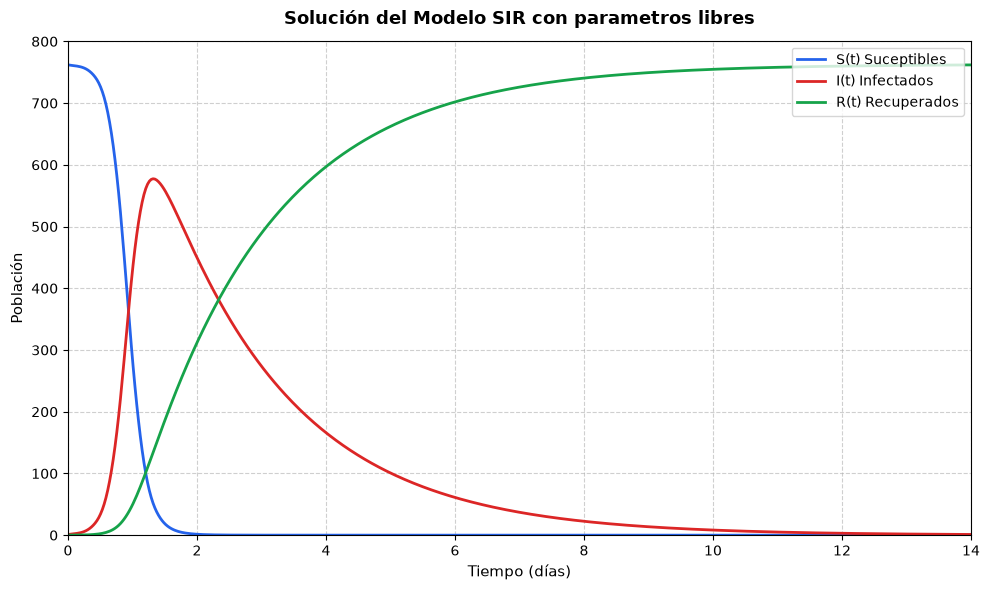

In [5]:
# 1. Puntos temporales donde solve_ivp evaluó la solución
S_pts, I_pts, R_pts = sol.T

# 2. Ajuste de splines cúbicos para cada compartimento
cs_S = CubicSpline(t_eval, S_pts)
cs_I = CubicSpline(t_eval, I_pts)
cs_R = CubicSpline(t_eval, R_pts)


# 3. Malla fina de tiempo para evaluar la interpolación suave
t_fine = np.linspace(t_eval[0], t_eval[-1], 500)
S_spline = cs_S(t_fine)
I_spline = cs_I(t_fine)
R_spline = cs_R(t_fine)

# 4. Graficación
plt.figure(figsize=(10, 6), dpi=100)

# Curvas continuas obtenidas con la interpolación por splines
plt.plot(t_fine, S_spline, label="S(t) Suceptibles", color="#2563eb", lw=2)
plt.plot(t_fine, I_spline, label="I(t) Infectados", color="#dc2626", lw=2)
plt.plot(t_fine, R_spline, label="R(t) Recuperados", color="#16a34a", lw=2)

# Personalización del gráfico
plt.title("Solución del Modelo SIR con parametros libres", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Tiempo (días)", fontsize=11)
plt.ylabel("Población", fontsize=11)
plt.xlim(t_eval[0], t_eval[-1])
plt.ylim(0, N * 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(frameon=True, fontsize=10, loc="upper right")
plt.tight_layout()
plt.show()


## Problema Inverso

Dado un conjunto de datos y un modelo o sistema de simulacion del que (se supone de antemano) provienen dichos datos, el problema inverso consiste en encontrar los parametros que lo definen.

En este caso, se tienen los datos del número de contagiados en un brote de influenza dentro de un internado en Inglaterra.

In [6]:
data = [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4]
t = np.arange(len(data))
n_poblacion = 763

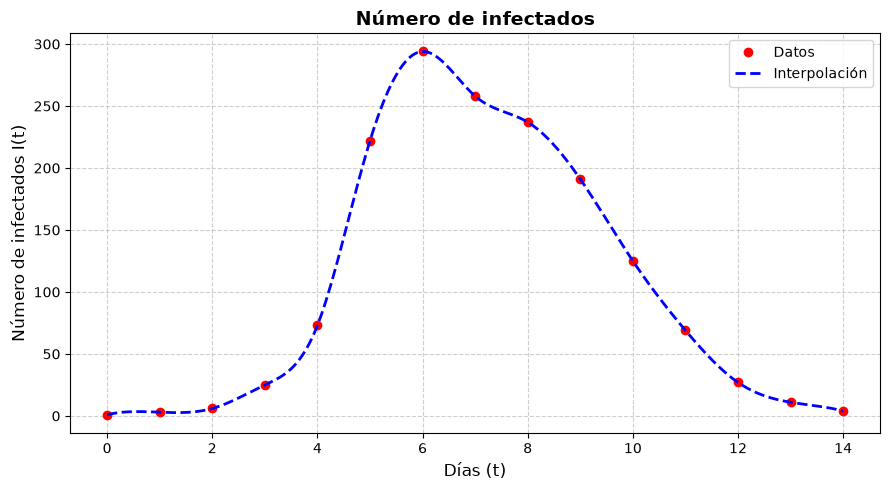

In [7]:
cs = CubicSpline(t, data)

# Generación de puntos densos para graficar la curva suave
t_denso = np.linspace(0,14, 300)
y_spline = cs(t_denso)

# Graficar
plt.figure(figsize=(9, 5))
plt.plot(t, data, "ro", label="Datos", markersize=6)
plt.plot(t_denso, y_spline, "b--", label="Interpolación", linewidth=2)

plt.title("Número de infectados", fontsize=14, fontweight="bold")
plt.xlabel("Días (t)", fontsize=12)
plt.ylabel("Número de infectados I(t)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

El problema entonces consiste en encontrar los parametros $\beta$ y $\gamma$ que mejor se ajusten a los datos observados. Sea $F(t) = (S(t), I(t), R(t))$ la solución al sistema (1), la solución se puede abordar de forma determinista mediante un problema de optimización por mínimos cuadrados o considerar la variación en los datos y abordarlo mediante regresión bayesiana, encontrando una distribución de probabilidad para los parametros.

## Estimación mediante regresión bayesiana

Considerando variaciones aleatorias en los datos, se asume que las observaciones (El numero de infectados $y_i$) proviene de una función determinista $\mu(t_i;\theta)$ (En este caso, $\mu$ es la solución $I$ del modelo epidemiologico) mas un ruido aleatorio $\epsilon_i$

$$y_i = \mu(t; \theta) + \epsilon_i$$

donde $\theta = (\beta, \gamma)$ son los parametros del modelo.

La estadistica bayesiana asume que los parametros $\theta$ son variables aleatorias con su propia distribucion de probabilidad cada una. Suponiendo una distribucion de probabilidad *a priori* de los parametros, por el teorema de Bayes, la distribucion se puede ajustar o actualizar en funcion de los datos $y$ dados:

$$ P(\theta | y) = \frac{P(y|\theta)P(\theta)}{P(y)}$$

donde

- Distribución a Priori ($P(\theta)$): Representa el conocimiento o suposiciones sobre los parámetros antes de ver los datos como el rango de valores posibles o distribuciones débilmente informativas (ej. $\theta \sim \mathcal{N}(0, 10)$).
- Función de Verosimilitud / Likelihood ($P(y \vert{} \theta)$): Mide qué tan probables son los datos observados si los parámetros $\theta$ tomaran un valor específico. Asumiendo que $\epsilon_i \sim \mathcal{N}(0,\sigma)$, la función de verosimilitud tiene la siguiente forma

    $$
    P(y|\theta) = \prod_{i=1}^{n} \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(-\frac{(y_i - \mu(x_i; \boldsymbol{\theta}))^2}{2\sigma^2}\right)
    $$

    Si no se tiene un conocimiento previo para definir la desviacion estandar $\sigma$, se agrega como un parametro mas, con su propia distribucion de probabilidad.

- Evidencia o Probabilidad Marginal ($P(y)$): Es la probabilidad total de observar los datos bajo todos los parámetros posibles.
- Distribución a Posteriori ($P(\theta \vert{} y)$): Es la distribución actualizada de los parámetros tras incorporar la evidencia de los datos.


### Distribuciones a priori

Las distribuciones a priori de los parametros se determinaran a partir de la informacion que conocemos de antemano tanto del modelo como de la naturaleza de los datos.

Para un analisis mas intuitivo y directo de los priors, las distribucion de los parametros base se deduciran a partir de las distribuciones de variables proxy. En el caso de $\gamma$ se usara la duracion media de infeccion $D$ (el tiempo promedio en que una persona es contagiosa). Mientras que para $\beta$ se usara el numero de reproductivo basico $R_0$ (Numero promedio de personas que una persona puede contagiar).

De antemano, tanto $D$, $R_0$ y $\sigma$ son estrictamente positivas, por lo que el soporte de sus distribuciones tiene que estar en $\mathbb{R}^+$. Para asegurar esta restriccion, las distribucion de los tres parametros sera una $\text{Log-Normal}(\eta, \tau)$, la cual tiene un soporte positivo. Dada una media esperada $m$ y una desviación estándar $s$, los parámetros $\mu$ y $\sigma$ de esta distribución se calculan como:

$$ \eta = \ln(m) - \frac{1}{2}\ln\left(1 + \frac{s^2}{m^2}\right), \quad \tau = \sqrt{\ln\left(1 + \frac{s^2}{m^2}\right)} $$

In [8]:
def log_normal_params(mu, sigma):
    eta = np.log(mu) - 0.5 * np.log(1 + (sigma**2 / mu**2))
    tau = np.sqrt(np.log(1 + (sigma**2 / mu**2)))
    return eta, tau

En el caso de $D$, la duración media de infección para un caso de influenza no grave varia entre los 5 a 7 dias, por lo que podemos establecer que la media de la distribucion prior de $D$ en 6, con una desviacion estandar igual a 1.5 para que la probabilidad se concentre entre esos 4.5 y 7.5 dias. Por lo que

In [9]:
log_normal_params(6, 1.5)

(np.float64(1.7614471583198374), np.float64(0.24622067706923975))

$$ \gamma \sim \text{Log-Normal}(1.76, 0.25) $$
Fuente: https://www.ncbi.nlm.nih.gov/sites/books/NBK513241/

Por otro lado, la distribucion de $\beta$ se basara en la que tiene el valor $R_0$ al tener una interpretacion mas directa. El numero de reproductivo basico $R_0$, en el caso de la influenza, ronda entre 1 a 3. Pero como los casos se dieron en un ambiente aislado y concentrado (un internado), es posible que este valor este subestimado a los datos. Por lo que la desviacion de la distribucion de $R_0$ sera lo suficientemente grande para que la mayor probabilidad abarque entre 1 a 6 con una media de 3.5 (desv. estandar igual a 2.5).


In [10]:
log_normal_params(3.5, 2.5)

(np.float64(1.0466405709485964), np.float64(0.6420629214442639))

$$ \log(R_0) \sim \text{Log-Normal}(1.05, 0.64) $$

Fuente: https://pmc.ncbi.nlm.nih.gov/articles/PMC4169819/

En cuanto a la desviacion estandar $\sigma$, se escogera un prior poco informativo.

$$\log(\sigma) \sim \mathcal{N}(0,1)$$

Por lo que los parametros que recibira el algoritmo son

$$\theta_{MCMC} = (D, R_0, \sigma)$$

## Implementacion mediante PyMC

El calculo de la distribucion a posteriori se puede realizar numericamente mediante el metodo de Monte Carlo via cadenas de Markov. Para la implementación de este metodo se recurrirá a la libreria PyMC que ejecuta esta metodologia mediante algoritmo sofisticados (HMC, NUTS, etc.).

In [11]:
# Se redefine la funcion del sistema con los parametros transformados
def sir_sist(y, t, theta):
    S, I, R = y[0], y[1], y[2]
    beta, gamma = theta[0], theta[1]

    dSdt = -beta/N * S * I
    dIdt = beta/N * S * I - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

# Generamos los tiempos enteros donde tenemos datos reales (excluyendo t0 = 0)
times_obs = np.arange(1, len(data))

# Se construye el solver que utilizaran los metodos de PyMC para resolver el sistema de edo
ode_model = DifferentialEquation(
    func=sir_sist,
    times=times_obs,
    n_states=3,
    n_theta=2,
    t0=0
    )

with pm.Model() as model:
  # Se declaran las variables proxy
  D = pm.LogNormal("D", mu=1.76, sigma=0.25)
  r0 = pm.LogNormal("r0", mu=1.05, sigma=0.64)
  sigma = pm.LogNormal("sigma", mu=0, sigma=1)

  # Se recuperan los parametros base del modelo
  gamma = pm.Deterministic('gamma', 1.0 / D)
  beta = pm.Deterministic('beta', r0 * gamma)

  # Se resuelve el sistema de edo
  sir_curves = ode_model(y0 = [N - 1, 1, 0], theta = [beta, gamma])

  # Se extrae la funcion I
  I_sim = sir_curves[:, 1]

  # Verosimilitud con distribucion Normal
  Y = pm.Normal("Y", mu=I_sim, sigma=sigma, observed=data[1:])

  prior = pm.sample_prior_predictive()
  trace = pm.sample(2000, tune = 1000, cores = 1, chains = 4, progressbar="split+stats")
  posterior = pm.sample_posterior_predictive(trace)

  trace.update(prior)
  trace.update(posterior)

  data_mcmc = trace


c:\Users\Ulises\anaconda3\envs\simulation-statistics\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run DifferentialEquation{func=<function sir_sist at 0x0000022DC53A77E0>, times=(np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)), n_states=3, n_theta=2, t0=0}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [D, Y, r0, sigma]
c:\Users\Ulises\anaconda3\envs\simulation-statistics\Lib\site-packages\pytensor\gradient.py:1327: FutureWarning: DifferentialEquation should implement `pullback` instead of `L_op`/`grad`. Direct `L_op`/`grad` implementations are deprecated and will stop being called in a future version.
  input_grads = node.op.pullback(inputs, node.outputs, new_output_grads)
Initializing NUTS using jitter+adapt_diag...
c:\Users\U

Output()

c:\Users\Ulises\anaconda3\envs\simulation-statistics\Lib\site-packages\pymc\ode\ode.py:133: ODEintWarning: Excess 
work done on this call (perhaps wrong Dfun type). Run with full_output = 1 to get quantitative information.
  sol = scipy.integrate.odeint(

c:\Users\Ulises\anaconda3\envs\simulation-statistics\Lib\site-packages\pymc\ode\ode.py:133: ODEintWarning: Illegal 
input detected (internal error). Run with full_output = 1 to get quantitative information.
  sol = scipy.integrate.odeint(

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2214 seconds.
c:\Users\Ulises\anaconda3\envs\simulation-statistics\Lib\site-packages\pytensor\link\numba\dispatch\basic.py:234: UserWarning: Numba will use object mode to run DifferentialEquation{func=<function sir_sist at 0x0000022DC53A77E0>, times=(np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)), n_states=3, n_theta=2, t0=0}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [Y]


Output()

In [12]:
az.summary(data_mcmc)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
D,2.284,0.08,2.2,2.4,2398,2888,1.00,0.0017,0.0015
r0,3.79,0.123,3.6,4,2353,2954,1.00,0.0026,0.0023
sigma,18.2,3.6,13,24,3364,3304,1.00,0.061,0.062
gamma,0.4384,0.0151,0.41,0.46,2398,2888,1.00,0.00031,0.00025
beta,1.6599,0.0247,1.6,1.7,9050,5643,1.00,0.00026,0.00032


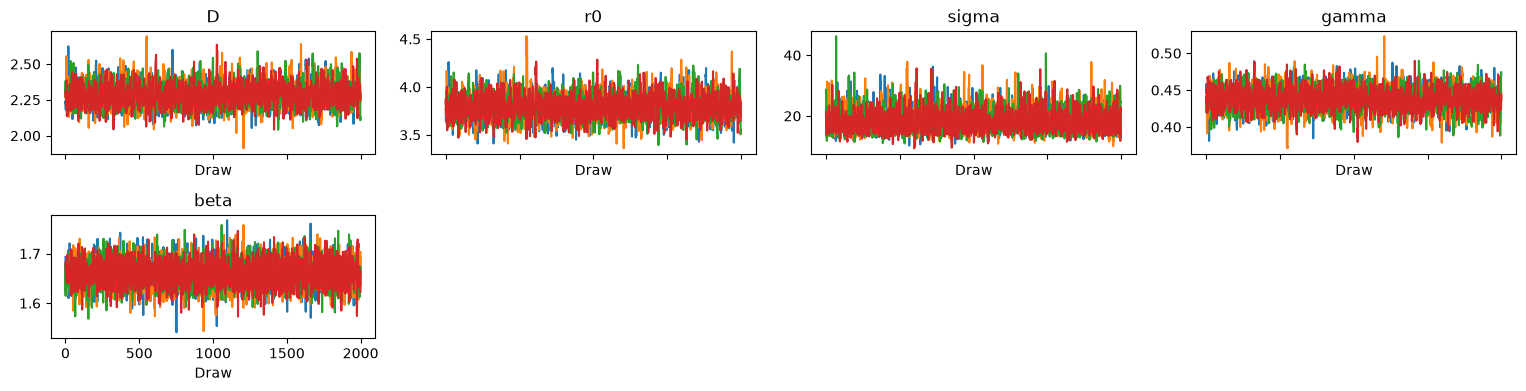

In [16]:
import matplotlib.pyplot as plt

# Graficar las trazas para verificar la convergencia
az.plot_trace(data_mcmc)
plt.tight_layout()
plt.show()

Parámetros promedio estimados:
Beta: 1.6599
Gamma: 0.4384



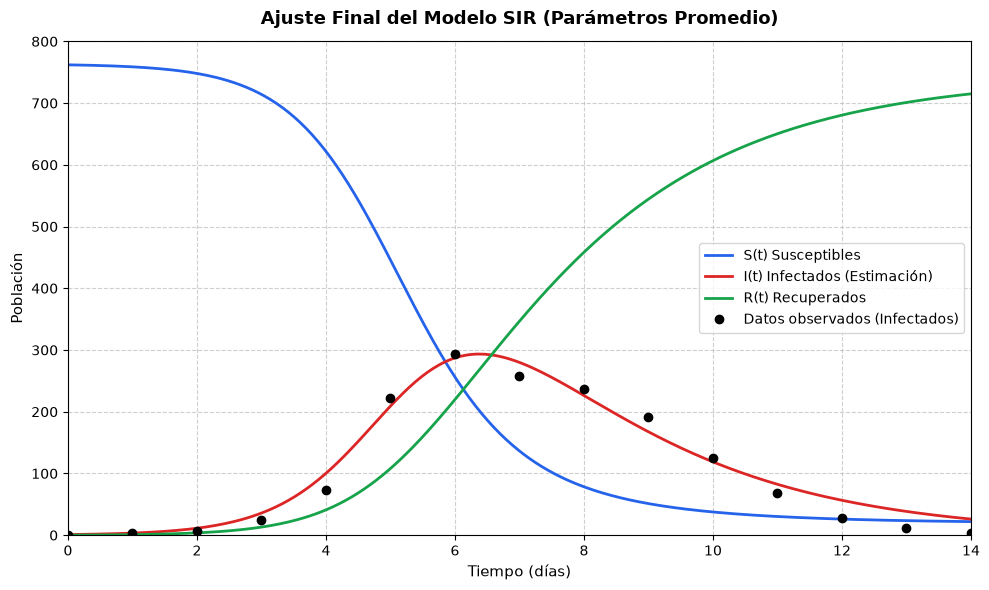

In [14]:
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

# Extraer la media de los parámetros a posteriori
beta_mean = data_mcmc.posterior["beta"].mean().item()
gamma_mean = data_mcmc.posterior["gamma"].mean().item()

print(f"Parámetros promedio estimados:\nBeta: {beta_mean:.4f}\nGamma: {gamma_mean:.4f}\n")

# Simular el modelo con los parámetros promedios
t_sim = np.linspace(0, 14, 300)
sol_est = odeint(func=sir_sist, y0=[n_poblacion - 1, 1, 0], t=t_sim, args=([beta_mean, gamma_mean],))
S_est, I_est, R_est = sol_est.T

# Graficar
plt.figure(figsize=(10, 6), dpi=100)
plt.plot(t_sim, S_est, label="S(t) Susceptibles", color="#2563eb", lw=2)
plt.plot(t_sim, I_est, label="I(t) Infectados (Estimación)", color="#dc2626", lw=2)
plt.plot(t_sim, R_est, label="R(t) Recuperados", color="#16a34a", lw=2)

# Añadir los datos observados
t_obs = np.arange(len(data))
plt.plot(t_obs, data, "ko", label="Datos observados (Infectados)", markersize=6, zorder=5)

plt.title("Ajuste Final del Modelo SIR (Parámetros Promedio)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Tiempo (días)", fontsize=11)
plt.ylabel("Población", fontsize=11)
plt.xlim(0, 14)
plt.ylim(0, n_poblacion * 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()